Plot Curve <br>
Objective: plot the average pixel intensities of thermal pictures against the blackbody temperature.

In [20]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
from skimage import io


In [21]:
data_path = 'data'  # The parent folder where the picture subfolders are stored

In [ ]:
# Determines the average pixel intensity of the image defined in the path.
# It then returns this pixel intensity average.
def readImage(image_path) :
    image = cv2.imread(image_path)
    if (image.ndim == 3):
        image = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)   # Convert it to grayscale
    avg_intensity = image.mean()                     # Get average pixel intensity across image
    return (avg_intensity)

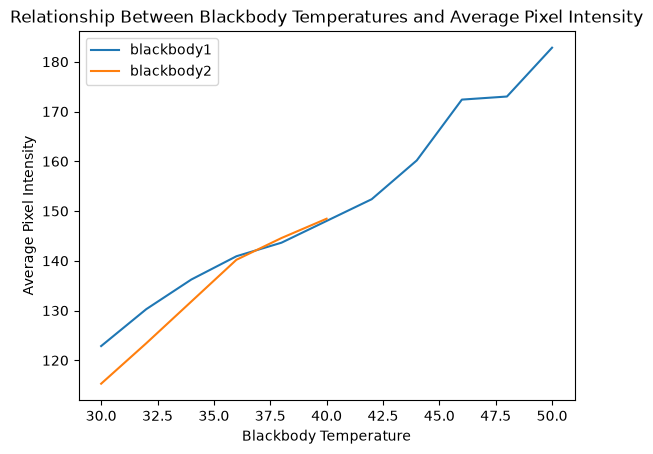

In [ ]:
blackbodies = ['blackbody1', 'blackbody2']
fig, ax = plt.subplots()
for blackbody in blackbodies:
    datapoints = np.empty((0, 2))
    path = data_path + "/" + blackbody
    for file in os.listdir(path):
        if file.endswith('.JPG'):                               # The ANAFI's thermal images are in .jpg format
            file = os.path.splitext(file)[0]
            x = file.partition('C')[0]                          # Get the temperature part of the filename
            x = float(x[:-1] + '.' + x[-1:])                    # Convert to float representation
            y = readImage('%s/%s.jpg' % (path,file))            # Get the image's avg pixel intensity
            datapoints = np.vstack([datapoints, np.array([x, y])])    # Add the (temperature, avg intensity) tuple to the array of plot points
    ax.plot(datapoints[:, 0], datapoints[:, 1], label = blackbody)

ax.set_title('Relationship Between Blackbody Temperatures and Average Pixel Intensity')
ax.set_xlabel('Blackbody Temperature (Celsius)')
ax.set_ylabel('Average Pixel Intensity')
ax.legend()

The resulting lines aren't as linear as expected. Try gamma decalibrating them.

In [45]:
def degammaCorrect(x):
    return (np.pow((x/255), 2.2) * 255)

In [48]:
def readImageDecorrect(image_path) :                        # The readimage function but with gamma decalibration
    image = cv2.imread(image_path)
    if (image.ndim == 3):
        image = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)   # Convert it to grayscale
    vectorized_func = np.vectorize(degammaCorrect)
    image = vectorized_func(image)
    avg_intensity = image.mean()                         # Get average pixel intensity across image
    return (avg_intensity)

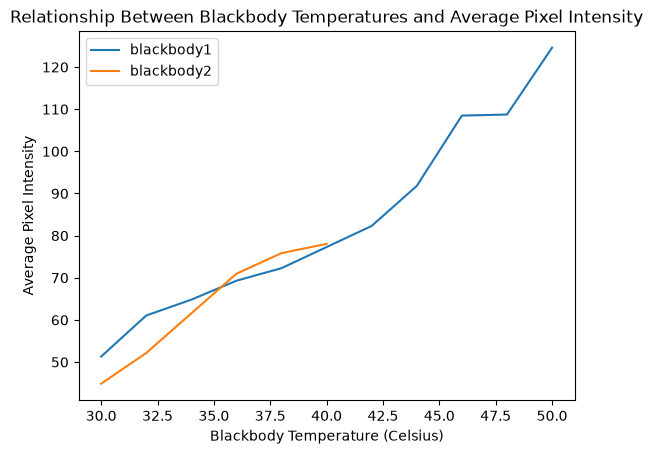

In [ ]:
# The same as before, but calling the modeified readImage function

blackbodies = ['blackbody1', 'blackbody2']
fig, ax = plt.subplots()
for blackbody in blackbodies:
    datapoints = np.empty((0, 2))
    path = data_path + "/" + blackbody
    for file in os.listdir(path):
        if file.endswith('.JPG'):                               # The ANAFI's thermal images are in JPEG format, with the .JPG extension
            file = os.path.splitext(file)[0]
            x = file.partition('C')[0]                          # Get the temperature part of the filename
            x = float(x[:-1] + '.' + x[-1:])                    # Convert to float representation
            y = readImageDecorrect('%s/%s.jpg' % (path,file))            # Get the image's avg pixel intensity
            datapoints = np.vstack([datapoints, np.array([x, y])])    # Add the (temperature, avg intensity) tuple to the array of plot points
    ax.plot(datapoints[:, 0], datapoints[:, 1], label = blackbody)

ax.set_title('Relationship Between Blackbody Temperatures and Average Pixel Intensity')
ax.set_xlabel('Blackbody Temperature (Celsius)')
ax.set_ylabel('Average Pixel Intensity (Gamma Decorrected)')
ax.legend()

Huh. Not very linear. Note to self, try recollecting data. But be more careful in picture taking this time.